In [1]:
import pandas as pd

df = pd.read_csv("GSAF_limpio_local.csv")
df.shape

(7125, 27)

In [2]:
df_pais = df[df["Country"] != "Unknown"]
df_pais.shape

(7075, 27)

In [ ]:
#contar cuantas veces aparece cada pais 

In [3]:
df_pais["Country"].value_counts()

Country
Usa             2597
Australia       1538
South africa     599
Bahamas          146
New zealand      146
                ... 
Djibouti           1
Bahrein            1
Korea              1
Red sea?           1
Asia?              1
Name: count, Length: 209, dtype: int64

In [ ]:
#solo los 10

In [5]:
df_pais["Country"].value_counts().head(10)

Country
Usa                 2597
Australia           1538
South africa         599
Bahamas              146
New zealand          146
Papua new guinea     136
Brazil               125
Mexico               107
Italy                 72
Fiji                  71
Name: count, dtype: int64

In [ ]:
# ver si cuales países concentran la mayoría de los registros. por porcentaje

In [6]:
(df_pais["Country"].value_counts(normalize=True) * 100).round(1).head(10)

Country
Usa                 36.7
Australia           21.7
South africa         8.5
Bahamas              2.1
New zealand          2.1
Papua new guinea     1.9
Brazil               1.8
Mexico               1.5
Italy                1.0
Fiji                 1.0
Name: proportion, dtype: float64

In [ ]:
# porcentaje acumulado de los 10 paises con mas registros
porcentajes = (df_pais["Country"].value_counts(normalize=True) * 100).round(1).head(10)
porcentajes.cumsum()

Country
Usa                 36.7
Australia           58.4
South africa        66.9
Bahamas             69.0
New zealand         71.1
Papua new guinea    73.0
Brazil              74.8
Mexico              76.3
Italy               77.3
Fiji                78.3
Name: proportion, dtype: float64

In [8]:
df_estado = df[df["State"] != "Unknown"]
df_estado.shape

(6637, 27)

In [9]:
# porcentaje acumulado de los 10 estados con más registros
porcentajes_estado = (df_estado["State"].value_counts(normalize=True) * 100).round(1).head(10)
porcentajes_estado.cumsum()

State
Florida                  18.1
New south wales          26.3
Queensland               31.7
Hawaii                   36.9
California               41.8
Western australia        45.6
Kwazulu-natal            48.9
Western cape province    51.9
South carolina           54.6
Eastern cape province    57.1
Name: proportion, dtype: float64

Florida concentra por sí sola el 18,1 % de los registros con estado conocido,
  y los 10 estados con más registros suman el 57,1 %, entre unos 900 estados 
 distintos. La concentración es menor que a nivel de país (78,3 % con 10 países),
  pero sigue siendo fuerte. Los 10 primeros pertenecen a solo tres países: EE. UU., Australia y Sudáfrica, 
 los mismos que dominaban el análisis por país.

In [ ]:
# buscamos saber los lugares concretod (playas, zonas)con más registros de ataques de tiburón. Para ello, vamos a filtrar los registros que tengan información sobre la localización concreta del ataque (columna "Location") y que no sea desconocida ("Unknown"). Luego, contaremos cuántas veces aparece cada localización y mostraremos las 10 con más registros.

In [10]:
df_loc = df[df["Location"] != "Unknown"]
df_loc.shape

(6555, 27)

In [11]:
# porcentaje acumulado de las 10 Location con más registros
porcentajes_loc = (df_loc["Location"].value_counts(normalize=True) * 100).round(1).head(10)
porcentajes_loc.cumsum()

Location
New smyrna beach, volusia county    3.0
Daytona beach, volusia county       3.5
Cocoa beach, brevard county         4.0
Ponce inlet, volusia county         4.4
Myrtle beach, horry county          4.7
Melbourne beach, brevard county     5.0
Isle of palms, charleston county    5.3
Durban                              5.6
Piedade                             5.8
Boa viagem, recife                  6.0
Name: proportion, dtype: float64

A nivel de lugar concreto la concentración es débil: los 10 lugares con más registros suman solo el 6,0 %, entre unos 4500 lugares distintos. Aun así, aparecen sobre todo zonas de la costa este de EE. UU. (Volusia y Brevard en Florida, Myrtle Beach y Charleston), lo que refuerza el patrón visto por país y estado.

# Qué estaba haciendo la gente cuando ocurrió el incidente

In [12]:
df_act = df[df["Activity"] != "Unknown"]
df_act.shape

(6535, 27)

In [13]:
# porcentaje acumulado de las 10 actividades con más registros
porcentajes_act = (df_act["Activity"].value_counts(normalize=True) * 100).round(1).head(10)
porcentajes_act.cumsum()

Activity
Surfing         17.8
Swimming        34.3
Fishing         42.2
Spearfishing    48.4
Wading          51.1
Bathing         53.7
Diving          56.1
Snorkeling      58.2
Standing        60.0
Scuba diving    61.6
Name: proportion, dtype: float64

Las actividades: las 3 primeras (surf, natación y pesca) suman el 42,2 % de los registros con actividad conocida, y las 10 primeras el 61,6 %, entre unas 1500 actividades distintas. Las más frecuentes son actividades acuáticas muy comunes, así que parte de esta concentración refleja simplemente lo que más hace la gente en el agua, no solo el riesgo.

# Qué especies de tiburón aparecen más en los registros.

In [14]:
df_esp = df[df["Species "] != "Unknown"]
df_esp.shape

(2533, 27)

In [15]:
# porcentaje acumulado de las 10 especies con más registros
porcentajes_esp = (df_esp["Species "].value_counts(normalize=True) * 100).round(1).head(10)
porcentajes_esp.cumsum()

Species 
White shark             8.1
Tiger shark            12.2
Bull shark             15.6
Wobbegong shark        16.8
Nurse shark            17.7
Blacktip shark         18.6
Blue shark             19.4
Mako shark             20.1
Bronze whaler shark    20.7
Raggedtooth shark      21.3
Name: proportion, dtype: float64

En las especies la concentración es débil: las 3 más frecuentes (tiburón blanco, tigre y toro) suman el 15,6 % y las 10 primeras el 21,3 % de los registros con especie conocida. Pero solo el 36 % de los registros dice la especie (el 64 % es “Unknown”), así que este resultado es poco fiable.

# Ver la dependecia de actividad y pais

In [16]:
top_paises = df_pais["Country"].value_counts().head(5).index
top_act = df_act["Activity"].value_counts().head(5).index

sub = df[df["Country"].isin(top_paises) & df["Activity"].isin(top_act)]
pd.crosstab(sub["Country"], sub["Activity"])

Activity,Fishing,Spearfishing,Surfing,Swimming,Wading
Country,,,,,
Australia,129,95,259,210,18
Bahamas,3,44,2,9,1
New zealand,19,12,17,22,2
South africa,48,51,100,95,9
Usa,148,66,674,392,124


In [17]:
(pd.crosstab(sub["Country"], sub["Activity"], normalize="index") * 100).round(1)

Activity,Fishing,Spearfishing,Surfing,Swimming,Wading
Country,,,,,
Australia,18.1,13.4,36.4,29.5,2.5
Bahamas,5.1,74.6,3.4,15.3,1.7
New zealand,26.4,16.7,23.6,30.6,2.8
South africa,15.8,16.8,33.0,31.4,3.0
Usa,10.5,4.7,48.0,27.9,8.8


La actividad depende del país: en EE. UU. casi la mitad de los registros es surf (48,0 %), mientras que en Bahamas el 74,6 % es pesca submarina. Australia y Sudáfrica tienen perfiles parecidos (surf y natación). Por tanto, la concentración por país no se debe a una única actividad.

# tabla resumen de todo

In [18]:
filas = []
for col in ["Country", "State", "Location", "Activity", "Species "]:
    conocidos = df[df[col] != "Unknown"][col]
    p = conocidos.value_counts(normalize=True) * 100
    filas.append({
        "Columna": col.strip(),
        "Registros conocidos": len(conocidos),
        "% Unknown": round((df[col] == "Unknown").mean() * 100, 1),
        "Valores distintos": conocidos.nunique(),
        "Top 1 %": round(p.iloc[0], 1),
        "Top 3 %": round(p.head(3).sum(), 1),
        "Top 10 %": round(p.head(10).sum(), 1),
    })

resumen_conc = pd.DataFrame(filas)
resumen_conc

,Columna,Registros conocidos,% Unknown,Valores distintos,Top 1 %,Top 3 %,Top 10 %
0,Country,7075,0.7,209,36.7,66.9,78.3
1,State,6637,6.8,916,18.1,31.6,57.0
2,Location,6555,8.0,4569,3.0,4.1,6.1
3,Activity,6535,8.3,1548,17.8,42.1,61.5
4,Species,2533,64.4,1349,8.1,15.6,21.4


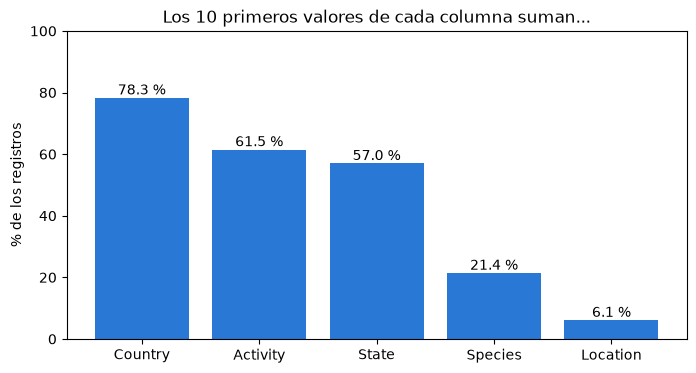

In [21]:
import matplotlib.pyplot as plt

columnas = ["Country", "Activity", "State", "Species ", "Location"]
top10 = []
for col in columnas:
    p = df[df[col] != "Unknown"][col].value_counts(normalize=True) * 100
    top10.append(round(p.head(10).sum(), 1))

nombres = [c.strip() for c in columnas]

plt.figure(figsize=(8, 4))
barras = plt.bar(nombres, top10, color="#2a78d6")
plt.bar_label(barras, fmt="%.1f %%")
plt.ylabel("% de los registros")
plt.title("Los 10 primeros valores de cada columna suman...")
plt.ylim(0, 100)
plt.show()

Conclusión general (Hipótesis 2)

La hipótesis se cumple, pero con distinta fuerza según el nivel geográfico. Los registros de incidentes con tiburón se concentran sobre todo por país: 3 países (EE. UU., Australia y Sudáfrica) suman el 66,9 % de los registros con país conocido, y los 10 primeros el 78,3 %, entre más de 200 países.

La concentración baja al mirar zonas más pequeñas: los 10 estados con más registros suman el 57,0 % (Florida sola, el 18,1 %), mientras que los 10 lugares concretos con más registros suman solo el 6,1 %, entre unos 4500. Aun así, los lugares con más registros están casi todos en la costa este de EE. UU.

Actividades: las 3 más frecuentes (surf, natación y pesca) suman el 42,1 % de los registros, y las 10 primeras el 61,5 %. La actividad depende del país: en EE. UU. el 48 % es surf, y en Bahamas el 74,6 % es pesca submarina.

Especies: la concentración es débil (las 10 primeras, el 21,4 %), pero el 64,4 % de los registros no indica la especie, así que este resultado es poco fiable.

Limitaciones: son registros documentados, no ataques reales. Países como EE. UU. y Australia pueden estar inflados por tener mejor sistema de notificación. Además, un mismo lugar o actividad puede estar escrito de varias formas, lo que subestima algo la concentración real.